# Email/SMS Spam Detection

**Task:** DS4  
**Data provenance:** UCI SMS Spam Collection, a public labelled text corpus.

This notebook calls a clearly separated, commented analysis module so the workflow can be run and maintained consistently. Run the cells from top to bottom. Metrics and plots are calculated at runtime; no results have been hand-entered. Synthetic-data outputs are demonstrations only.

## Notebook roadmap
This executed notebook separates data preparation, visualization, model training or analysis, and evaluation. Figures appear inline; each chart is followed by a written interpretation.

## Data Loading / EDA
Load the task dataset, verify its provenance and structure, and inspect its first descriptive summaries before visual or model analysis.

In [1]:
from pathlib import Path
import sys
project = Path.cwd().resolve()
if not (project / 'analysis_tasks.py').is_file():
    raise FileNotFoundError('Run Jupyter with this task folder as the working directory.')
sys.path.insert(0, str(project))
from analysis_tasks import *
from IPython.display import display
OUT_DIR.mkdir(exist_ok=True)
_chart_index = 0
_original_show = plt.show
def _save_inline_figure(*args, **kwargs):
    global _chart_index
    if plt.get_fignums():
        plt.gcf().savefig(OUT_DIR / f'notebook_chart_{_chart_index + 1:02d}.png', dpi=150, bbox_inches='tight')
        _chart_index += 1
    return _original_show(*args, **kwargs)
plt.show = _save_inline_figure


In [2]:
print("TF-IDF weights words by term frequency in a message and inverse document frequency across messages.")

data = DATA_DIR / "SMSSpamCollection"

if not data.exists():
        raise FileNotFoundError(f"Dataset not found at {data}. See this task's README.md for setup instructions.")

df = pd.read_csv(data, sep="\t", header=None, names=["label", "text"], encoding="utf-8")

report(df)

print(df.label.value_counts(normalize=True).mul(100).round(2).astype(str) + "%")

TF-IDF weights words by term frequency in a message and inverse document frequency across messages.
Shape: (5572, 2)

Dtypes:
 label    str
text     str
dtype: object

Nulls:
 label    0
text     0
dtype: int64

Descriptive statistics:
       count unique                     top  freq
label  5572      2                     ham  4825
text   5572   5169  Sorry, I'll call later    30
label
ham     86.59%
spam    13.41%
Name: proportion, dtype: str


## Visualizations
Charts below are also saved as PNG files under `outputs/`. Read each finding before interpreting subsequent figures.

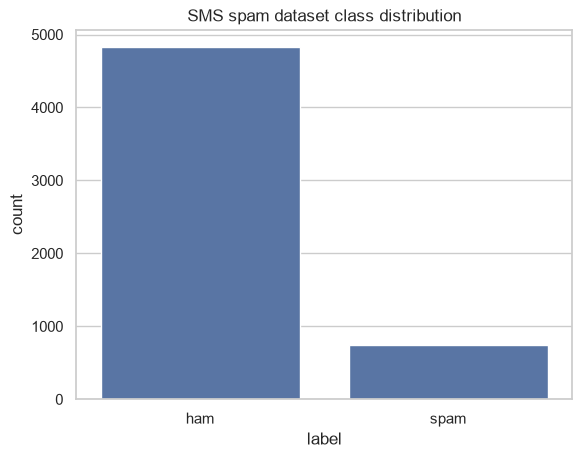

In [3]:
sns.countplot(data=df, x="label")

plt.title("SMS spam dataset class distribution")

plt.show()

### Chart 1 interpretation
The class-count plot shows the relative prevalence of ham and spam. With an imbalanced inbox, accuracy alone can hide missed spam; review per-class recall and precision.

In [4]:
df["clean_text"] = df.text.str.lower().str.translate(str.maketrans("", "", string.punctuation))

## Model Training / Analysis
Fit and compare appropriate models, or perform the task-specific analytical transformation where supervised model training does not apply.

In [5]:
x_train, x_test, y_train, y_test = train_test_split(df.clean_text, df.label, test_size=.2, random_state=SEED, stratify=df.label)

vectorizer = TfidfVectorizer(stop_words="english", min_df=2, ngram_range=(1, 2))

x_train_vec, x_test_vec = vectorizer.fit_transform(x_train), vectorizer.transform(x_test)

results = [
        score_classifier("Multinomial Naive Bayes", MultinomialNB(), x_train_vec, x_test_vec, y_train, y_test),
        score_classifier("Logistic Regression", LogisticRegression(max_iter=1000), x_train_vec, x_test_vec, y_train, y_test),
    ]

best = max(results, key=lambda row: row["f1"])

mistakes = pd.DataFrame({"text": x_test, "actual": y_test, "predicted": best["prediction"]})

print("Misclassified examples:\n", mistakes[mistakes.actual != mistakes.predicted].head(5).to_string(index=False))

print("Spam recall matters because missed spam still reaches a user's inbox; precision is also important to avoid hiding legitimate messages.")


Multinomial Naive Bayes: accuracy=0.963, macro-F1=0.910
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.72      0.84       149

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115

Confusion matrix:
 [[966   0]
 [ 41 108]]

Logistic Regression: accuracy=0.968, macro-F1=0.922
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.76      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115

Confusion matrix:
 [[966   0]
 [ 36 113]]
Misclassified examples:
                                                                                                                                

## Evaluation
Review the held-out metrics or descriptive analysis summary below. Predictive scores apply only to the documented dataset and split; non-predictive tasks report their analytical result and dataset coverage instead.

In [6]:
evaluation_rows = []
for variable in ('results', 'models', 'result'):
    candidate = globals().get(variable)
    candidates = candidate if isinstance(candidate, list) else [candidate]
    for row in candidates:
        if isinstance(row, dict):
            metrics = {key: value for key, value in row.items()
                       if isinstance(value, (int, float, np.number))
                       and not isinstance(value, (bool, np.bool_))}
            if metrics:
                evaluation_rows.append({'model': row.get('name', variable), **metrics})
if not evaluation_rows and {'y_test', 'pred'}.issubset(globals()):
    from sklearn.metrics import precision_score, recall_score, f1_score
    evaluation_rows.append({'model': 'Fraud holdout at threshold 0.50',
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0)})
if evaluation_rows:
    evaluation = pd.DataFrame(evaluation_rows)
elif isinstance(globals().get('summary'), pd.DataFrame):
    evaluation = summary.copy()
elif isinstance(globals().get('profile'), pd.DataFrame):
    evaluation = profile.copy()
elif isinstance(globals().get('monthly'), pd.Series):
    evaluation = monthly.rename('revenue').to_frame()
else:
    evaluation = pd.DataFrame([{'analysis': 'SMS Spam Detection',
        'rows': len(df) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'columns': len(df.columns) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'charts': _chart_index}])
display(evaluation)
evaluation_path = OUT_DIR / 'evaluation_summary.csv'
evaluation.to_csv(evaluation_path, index=True)
print(f'Saved {_chart_index} chart(s) and evaluation summary: {evaluation_path}')

,model,accuracy,f1
0,Multinomial Naive Bayes,0.963229,0.909843
1,Logistic Regression,0.967713,0.922151


Saved 1 chart(s) and evaluation summary: D:\Oasis\DataScience-Task4-SMSSpamDetection\outputs\evaluation_summary.csv
